# FNEWS — Image modeling

**Research objective.** Saved ResNet-18 transfer-learning evidence, preprocessing, validation evaluation, and its task limitations.

This consolidated notebook reuses saved, executed research evidence. It does not train models or perform new held-out-test selection. `SOURCE_TRUE` and `SOURCE_NON_TRUE` are Fakeddit source-taxonomy labels, not independent real-world fact-checking verdicts.

In [ ]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
if not (ROOT / "data/research_dataset").exists():
    ROOT = Path("/Users/aka_ank/Desktop/FNEWS")
DATA = ROOT / "data/research_dataset"
REPORTS = ROOT / "reports"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.titlesize": 13, "axes.labelsize": 11})

def paired(split):
    frame = pd.read_parquet(DATA / "manifests" / f"{split}_manifest.parquet")
    return frame.loc[(frame.source_dataset == "Fakeddit") & (frame.download_status == "verified_reused_or_processed")].copy().reset_index(drop=True)

def canonical_source_labels(raw):
    """Fakeddit raw 1=true; return 0=SOURCE_TRUE, 1=SOURCE_NON_TRUE."""
    return 1 - np.asarray(raw, dtype=int)

def source_names(values):
    return np.where(np.asarray(values) == 0, "SOURCE_TRUE", "SOURCE_NON_TRUE")

def show_frame(frame, rows=10):
    display(frame.head(rows))


## ResNet-18 transfer learning

_Source preserved from `notebooks/archive/2026-10-27/research/05_image_model_training.ipynb`._

## ResNet-18 transfer learning

The image model uses ImageNet-pretrained ResNet-18 preprocessing and a two-class classification head. Image-only prediction can recognize source-correlated visual patterns but cannot verify a claim’s factual status.

,epoch,train_loss,validation_macro_f1
0,1,0.670777,0.611393
1,2,0.597806,0.612230
2,3,0.572267,0.686088
3,4,0.562400,0.676365


History columns: ['epoch', 'train_loss', 'validation_macro_f1']


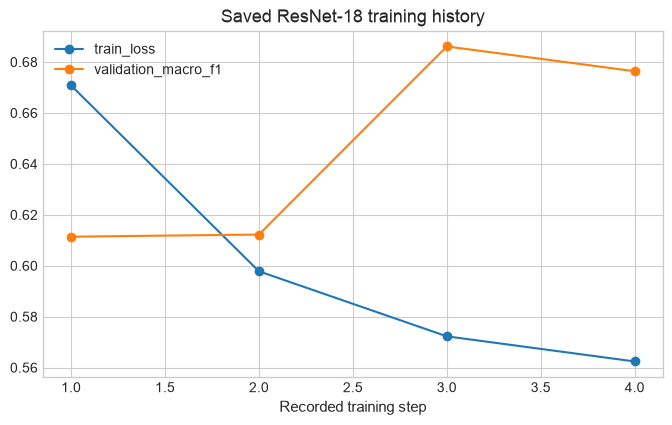

In [2]:
history=pd.read_csv(REPORTS/'experiments/research_dataset_baselines/resnet18_frozen/history.csv');display(history.head());print('History columns:',history.columns.tolist())
ax=history.plot(x=history.columns[0],y=[c for c in history.columns if c!=history.columns[0]],marker='o',title='Saved ResNet-18 training history');ax.set_xlabel('Recorded training step');plt.show()

In [3]:
pred=pd.read_parquet(REPORTS/'experiments/research_dataset_baselines/resnet18_frozen/validation_predictions.parquet');y=canonical_source_labels(pred.label);p=canonical_source_labels(pred.prediction);from sklearn.metrics import confusion_matrix,f1_score
cm=confusion_matrix(y,p,labels=[0,1]);print('Canonical [SOURCE_TRUE,SOURCE_NON_TRUE] matrix:',cm.tolist());print('Macro-F1:',f1_score(y,p,average='macro'));display(pd.DataFrame(cm,index=['SOURCE_TRUE','SOURCE_NON_TRUE'],columns=['SOURCE_TRUE','SOURCE_NON_TRUE']))

Canonical [SOURCE_TRUE,SOURCE_NON_TRUE] matrix: [[252, 125], [161, 395]]
Macro-F1: 0.6860877135193637


,SOURCE_TRUE,SOURCE_NON_TRUE
SOURCE_TRUE,252,125
SOURCE_NON_TRUE,161,395


## Interpretation

The saved 933-pair validation audit has source-true recall 66.84%, source-non-true recall 71.04%, and macro-F1 68.61%. These are source-taxonomy results, not claim-factuality results. Use image signals only alongside explicit task boundaries.

## Reproducibility and limitations

The original notebooks remain unchanged under `notebooks/archive/2026-10-27/`. Rebuild this active suite with `python scripts/consolidate_notebooks.py`. Archived outputs are historical records, not claims of a new execution.